# Sandboxed agent — inspecting an isolated workspace

[Open Colab](https://colab.research.google.com/) and choose **File → Upload notebook** to open this English copy.

**Audience** — Developers new to agents who are familiar with Python functions and async/await.

**Learning objective** — Define a manifest, connect a shell capability, run a sandboxed agent, and clean up its session.

**Sequence** — Set up the environment, define inputs and agents, run the workflow, check the results, then try an exercise.

[Source code](../src/main.py) · [Example guide](../README.md) · [Environment setup](../../../../../docs/setup.md)

### Pattern architecture

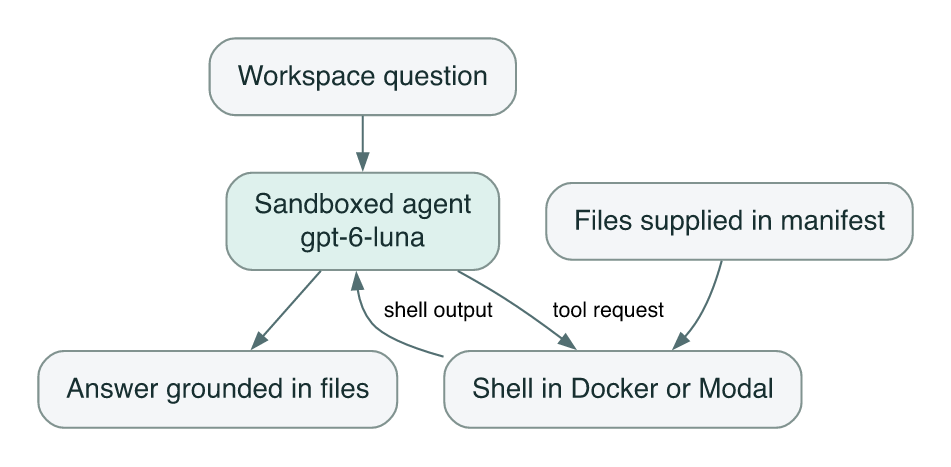

### From diagram to code

| Diagram element | Implementation | Role |
| --- | --- | --- |
| User Query | `question` | Request to inspect the workspace |
| Agent Harness | `Runner.run()` and `SandboxRunConfig` | Connect the agent run to a sandbox session |
| Sandboxed Agent | `SandboxAgent` | Uses tools inside the isolated environment |
| Filesystem | `Manifest` and `File` | Define the initial files in the sandbox |
| Shell | `WorkspaceShellCapability` | Executes commands inside the sandbox |
| Packages | Docker or Modal sandbox image | Provides the isolated environment and installed packages |
| Output | `sandbox_result.final_output` | Answer based on the inspected files |

#### Execution flow

1. Declare the files for the agent to inspect in the `Manifest`.
2. Connect the shell tool to the sandbox session with `WorkspaceShellCapability`.
3. Use `sandbox_session()` to create and start an isolated session on the selected backend.
4. Use `Runner.run()` to run the `SandboxAgent` in that session.
5. Clean up the session when the run ends. If using Docker, also close the connection.

#### How the example implements the diagram

The diagram shows common sandbox features: a filesystem, shell, packages, and artifacts. This notebook supplies the initial files and shell capability. Packages come from the selected backend image. Artifact generation is outside the exercise.

## 1. Set up the environment

### Colab

1. In Colab, choose **File → Upload notebook** and select this `.ipynb` file. A CPU runtime is sufficient. You can run it without cloning the repository or mounting Google Drive.
2. The setup cell installs `openai-agents[modal]==0.22.1` and `python-dotenv` if needed. If you already imported a different SDK version, restart the runtime and run from the top.
3. For live calls, open **Secrets** (the key icon in the left sidebar), add your existing key as `OPENAI_API_KEY`, and enable access for this notebook. Keep keys out of code cells. Your local `.env.local` file is not copied into Colab.

### Local Jupyter

Install the shared notebook environment with `uv` and select its kernel. Existing environment variables take precedence. If a `.env.local` file exists in the current directory or a parent, the notebook reads additional settings from it. Offline exercises require neither the file nor a key.

### Run settings

The default `RUN_API=False` builds the agents and runs offline exercises without reading Secrets or calling the API. To see live results, set `RUN_API=True` in the next cell and run the following cells in order. Key lookup order is **environment → optional `.env.local` → Colab Secrets**. The notebook never prints or saves key values. Model calls and web searches may incur charges. Jupyter supports top-level `await` in its existing event loop.

The standalone example later in the notebook has its own `run_api=True` argument, independent of `RUN_API`.

### Sandbox runtime

The sandbox backend creates the agent's isolated workspace and runs commands there. **Modal** runs code in the cloud. A **Modal Sandbox** is an isolated container you can create on demand to work with files and run shell commands. See the [Modal Sandbox guide](https://modal.com/docs/guide/sandboxes).

Each component has a distinct role in this example.

| Component | Role |
| --- | --- |
| Colab | Runs the notebook and agent workflow and processes tool results. |
| OpenAI API | Generates model responses and requests to call tools. |
| Modal Sandbox | Hosts the files defined in the `Manifest` and provides the remote workspace for shell inspection. |

The notebook creates the workspace in Modal and receives the results of shell commands requested by the agent. Colab needs no local Docker daemon. Configure Modal authentication to access the remote workspace and `OPENAI_API_KEY` to call the model.

- Docker is the local default. Colab defaults to remote Modal Sandbox. Choose explicitly with `SANDBOX_BACKEND`.
- For live Colab runs, create a Modal API token in your account settings. Add `MODAL_TOKEN_ID` and `MODAL_TOKEN_SECRET` to Colab Secrets and grant notebook access. You also need `OPENAI_API_KEY`.
- Keep tokens in the Colab runtime for authentication. Leave them out of the manifest and sandbox files. With `RUN_API=False`, the notebook skips token lookup and remote resource creation.
- Modal may charge separately. The notebook attempts deletion at the end and sets a maximum lifetime of 300 seconds. Check the Modal dashboard if a forced shutdown interrupts cleanup.
- See [Modal's authentication documentation](https://modal.com/docs/reference/modal.config). To select Modal locally, install `openai-agents[modal]==0.22.1` and configure authentication.


In [ ]:
import os
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

# Install only in Colab. Local environments use requirements-notebooks.txt.
try:
    import google.colab
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    try:
        dependencies_ready = (
            version("openai-agents") == "0.22.1"
            and version("python-dotenv").split(".")[0] == "1"
            and version("modal") == "1.4.3"
        )
    except PackageNotFoundError:
        dependencies_ready = False
    if not dependencies_ready:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "--quiet",
            "openai-agents[modal]==0.22.1", "python-dotenv>=1,<2",
        ])

from agents import RunConfig, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


RUN_API = False  # Set True for the walkthrough's API and web search calls.
MODEL = load_environment(run_api=RUN_API)
set_tracing_disabled(True)
print({"environment": "Colab" if IN_COLAB else "local", "model": MODEL, "api_enabled": RUN_API})


## 2. Set up the sandbox API and model

Local Docker execution requires a running Docker daemon. Colab uses remote Modal Sandbox. `SANDBOX_MODEL` defaults to `gpt-6-luna`.


In [ ]:
from agents import ModelSettings
from agents.sandbox import Manifest, SandboxAgent, SandboxRunConfig
from agents.sandbox.config import DEFAULT_PYTHON_SANDBOX_IMAGE
from agents.sandbox.entries import File

SANDBOX_MODEL = os.getenv("SANDBOX_MODEL", "gpt-6-luna")

from contextlib import asynccontextmanager


def sandbox_backend() -> str:
    try:
        import google.colab
    except ImportError:
        default = "docker"
    else:
        default = "modal"
    backend = os.getenv("SANDBOX_BACKEND", default)
    if backend not in {"docker", "modal"}:
        raise ValueError("SANDBOX_BACKEND must be docker or modal.")
    return backend


def load_modal_credentials() -> None:
    # Local Modal can use its existing CLI profile. Colab uses Secrets or env vars.
    try:
        from google.colab import userdata
    except ImportError:
        return
    for name in ("MODAL_TOKEN_ID", "MODAL_TOKEN_SECRET"):
        if os.getenv(name, "").strip():
            continue
        try:
            value = userdata.get(name)
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                f"Add {name} to Colab Secrets and enable Notebook access."
            ) from None
        if not isinstance(value, str) or not value.strip():
            raise RuntimeError(f"Colab Secret {name} is empty.")
        os.environ[name] = value.strip()


@asynccontextmanager
async def sandbox_session(manifest):
    """Use remote Modal in Colab or Docker locally; always attempt cleanup."""
    backend = sandbox_backend()
    docker_api = None
    client = None
    session = None
    try:
        if backend == "modal":
            load_modal_credentials()
            from agents.extensions.sandbox import ModalSandboxClient, ModalSandboxClientOptions
            client = ModalSandboxClient()
            options = ModalSandboxClientOptions(
                app_name=os.getenv("MODAL_APP_NAME", "agent-pattern-examples"),
                timeout=300,
            )
        else:
            from docker import from_env
            from agents.sandbox.sandboxes.docker import DockerSandboxClient, DockerSandboxClientOptions
            docker_api = from_env()
            docker_api.ping()
            client = DockerSandboxClient(docker_api)
            options = DockerSandboxClientOptions(image=DEFAULT_PYTHON_SANDBOX_IMAGE)
        session = await client.create(manifest=manifest, options=options)
        await session.start()
        async with session:
            yield session
    finally:
        try:
            if session is not None:
                await client.delete(session)
        finally:
            if docker_api is not None:
                docker_api.close()

print({"sandbox_backend": sandbox_backend()})


## 3. Connect the shell tool

The cell defines the same helper class as the local source. It forwards shell requests to the current sandbox session's command executor.

In [ ]:
from __future__ import annotations

from agents.sandbox import Capability, Manifest
from agents.sandbox.session.base_sandbox_session import BaseSandboxSession
from agents.tool import (
    ShellCallOutcome,
    ShellCommandOutput,
    ShellCommandRequest,
    ShellResult,
    ShellTool,
    Tool,
)


class WorkspaceShellCapability(Capability):
    """Expose one shell tool for inspecting the active sandbox workspace."""

    def __init__(self) -> None:
        super().__init__(type="workspace_shell")
        self._session: BaseSandboxSession | None = None

    def bind(self, session: BaseSandboxSession) -> None:
        self._session = session

    def tools(self) -> list[Tool]:
        return [ShellTool(executor=self._execute_shell)]

    async def instructions(self, manifest: Manifest) -> str | None:
        _ = manifest
        return (
            "Use the `shell` tool to inspect the sandbox workspace before answering. "
            "The workspace root is the current working directory, "
            "so prefer relative paths "
            "with commands like `pwd`, `find .`, and `cat`. "
            "Only cite files you actually read."
        )

    async def _execute_shell(self, request: ShellCommandRequest) -> ShellResult:
        if self._session is None:
            raise RuntimeError("Workspace shell is not bound to a sandbox session.")

        # Zero is intentionally equivalent to no explicit Shell action timeout.
        timeout_ms = request.data.action.timeout_ms
        timeout_s = timeout_ms / 1000 if timeout_ms else None
        outputs: list[ShellCommandOutput] = []

        for command in request.data.action.commands:
            result = await self._session.exec(
                command,
                timeout=timeout_s,
                shell=True,
            )
            outputs.append(
                ShellCommandOutput(
                    command=command,
                    stdout=result.stdout.decode("utf-8", errors="replace"),
                    stderr=result.stderr.decode("utf-8", errors="replace"),
                    outcome=ShellCallOutcome(
                        type="exit",
                        exit_code=result.exit_code,
                    ),
                )
            )

        return ShellResult(output=outputs)

## 4. Define the workspace files and agent

Provide just the two small files below so the agent can inspect them without mounting an entire host directory.

In [ ]:
manifest = Manifest(
    entries={
        "README.md": File(content=b"# Demo Project\nA tiny greeting application.\n"),
        "src/app.py": File(
            content=b'def greet(name):\n    return f"Hello, {name}!"\n'
        ),
    }
)

workspace_agent = SandboxAgent(
    name="Workspace inspector",
    model=SANDBOX_MODEL,
    instructions=(
        "Inspect the files with shell and explain what the project does in two "
        "sentences. Only describe files you actually inspected."
    ),
    default_manifest=manifest,
    capabilities=[WorkspaceShellCapability()],
    model_settings=ModelSettings(tool_choice="required"),
)

question = "Read README.md and src/app.py, then summarize this project."

## 5. Create, run, and clean up the sandbox (API and sandbox calls)

`sandbox_session()` creates a local Docker or remote Modal session. After success or failure it attempts deletion in `finally` and closes any Docker connection. Modal sessions have a maximum lifetime of 300 seconds. Deletion itself can fail.


In [ ]:
sandbox_result = None

if RUN_API:
    async with sandbox_session(manifest) as session:
        sandbox_result = await Runner.run(
            workspace_agent,
            question,
            max_turns=6,
            run_config=RunConfig(sandbox=SandboxRunConfig(session=session)),
        )
        print(sandbox_result.final_output)
else:
    print("Sandbox and API execution skipped; Agent and Manifest definitions are ready.")


## 6. Verify that the tool ran

Inspect the run for a shell tool call to confirm the agent used the workspace to answer.

In [ ]:
if sandbox_result is not None:
    calls = [
        item
        for item in sandbox_result.new_items
        if item.type == "tool_call_item"
    ]

    assert calls, "No shell tool calls were made."
    assert str(sandbox_result.final_output).strip()

    print({"tool_calls": len(calls)})

## 7. Run the workflow as a Python module with `main()`

The preceding cells walk through the workflow step by step. The next cell packages the same workflow as an independent Python module. Once the dependencies are installed, you can start with this cell because it defines its own agents and variables.

Use `main()` as the entry point and package workspace creation, shell inspection, result handling, and session deletion in a reusable function. This version uses the same files, shell tool, default model, and turn limit as the guided exercise.

| Component | Responsibility |
| --- | --- |
| `StandaloneWorkspaceShellCapability` | Routes shell requests to command execution in the sandbox session |
| `build_workspace_agent()` | Configures the manifest and creates a SandboxAgent |
| `inspect_workspace()` | Creates and starts a Docker or Modal session, runs the agent, checks the result, and cleans up |
| `main()` | Loads settings, determines whether to run, passes the input, and prints the result |

Each run creates a fresh session. After session creation, a `finally` block attempts deletion even if execution fails. A separate `finally` closes the Docker connection, including on session creation or deletion errors. A failed container deletion propagates an error and can leave the container behind.

With `run_api=False`, the default, the example skips both sandbox and API calls. Live local Docker execution requires a running daemon. Colab needs Modal tokens. Set `SANDBOX_MODEL` in the environment or optional `.env.local` file. It defaults to `gpt-6-luna` and is independent of `AGENT_MODEL`.


In [ ]:
from __future__ import annotations

import asyncio
import os

from agents import ModelSettings, RunConfig, Runner, set_tracing_disabled
from agents.sandbox import Capability, Manifest, SandboxAgent, SandboxRunConfig
from agents.sandbox.config import DEFAULT_PYTHON_SANDBOX_IMAGE
from agents.sandbox.entries import File
from agents.sandbox.session.base_sandbox_session import BaseSandboxSession
from agents.tool import (
    ShellCallOutcome,
    ShellCommandOutput,
    ShellCommandRequest,
    ShellResult,
    ShellTool,
    Tool,
)
from dotenv import find_dotenv, load_dotenv


from contextlib import asynccontextmanager


def sandbox_backend() -> str:
    try:
        import google.colab
    except ImportError:
        default = "docker"
    else:
        default = "modal"
    backend = os.getenv("SANDBOX_BACKEND", default)
    if backend not in {"docker", "modal"}:
        raise ValueError("SANDBOX_BACKEND must be docker or modal.")
    return backend


def load_modal_credentials() -> None:
    # Local Modal can use its existing CLI profile. Colab uses Secrets or env vars.
    try:
        from google.colab import userdata
    except ImportError:
        return
    for name in ("MODAL_TOKEN_ID", "MODAL_TOKEN_SECRET"):
        if os.getenv(name, "").strip():
            continue
        try:
            value = userdata.get(name)
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                f"Add {name} to Colab Secrets and enable Notebook access."
            ) from None
        if not isinstance(value, str) or not value.strip():
            raise RuntimeError(f"Colab Secret {name} is empty.")
        os.environ[name] = value.strip()


@asynccontextmanager
async def sandbox_session(manifest):
    """Use remote Modal in Colab or Docker locally; always attempt cleanup."""
    backend = sandbox_backend()
    docker_api = None
    client = None
    session = None
    try:
        if backend == "modal":
            load_modal_credentials()
            from agents.extensions.sandbox import ModalSandboxClient, ModalSandboxClientOptions
            client = ModalSandboxClient()
            options = ModalSandboxClientOptions(
                app_name=os.getenv("MODAL_APP_NAME", "agent-pattern-examples"),
                timeout=300,
            )
        else:
            from docker import from_env
            from agents.sandbox.sandboxes.docker import DockerSandboxClient, DockerSandboxClientOptions
            docker_api = from_env()
            docker_api.ping()
            client = DockerSandboxClient(docker_api)
            options = DockerSandboxClientOptions(image=DEFAULT_PYTHON_SANDBOX_IMAGE)
        session = await client.create(manifest=manifest, options=options)
        await session.start()
        async with session:
            yield session
    finally:
        try:
            if session is not None:
                await client.delete(session)
        finally:
            if docker_api is not None:
                docker_api.close()


class StandaloneWorkspaceShellCapability(Capability):
    """Expose one shell tool for inspecting the active sandbox workspace."""

    def __init__(self) -> None:
        super().__init__(type="workspace_shell")
        self._session: BaseSandboxSession | None = None

    def bind(self, session: BaseSandboxSession) -> None:
        self._session = session

    def tools(self) -> list[Tool]:
        return [ShellTool(executor=self._execute_shell)]

    async def instructions(self, manifest: Manifest) -> str | None:
        _ = manifest
        return (
            "Use the `shell` tool to inspect the sandbox workspace before answering. "
            "The workspace root is the current working directory, "
            "so prefer relative paths "
            "with commands like `pwd`, `find .`, and `cat`. "
            "Only cite files you actually read."
        )

    async def _execute_shell(self, request: ShellCommandRequest) -> ShellResult:
        if self._session is None:
            raise RuntimeError("Workspace shell is not bound to a sandbox session.")

        # Zero is intentionally equivalent to no explicit Shell action timeout.
        timeout_ms = request.data.action.timeout_ms
        timeout_s = timeout_ms / 1000 if timeout_ms else None
        outputs: list[ShellCommandOutput] = []

        for command in request.data.action.commands:
            result = await self._session.exec(
                command,
                timeout=timeout_s,
                shell=True,
            )
            outputs.append(
                ShellCommandOutput(
                    command=command,
                    stdout=result.stdout.decode("utf-8", errors="replace"),
                    stderr=result.stderr.decode("utf-8", errors="replace"),
                    outcome=ShellCallOutcome(
                        type="exit",
                        exit_code=result.exit_code,
                    ),
                )
            )

        return ShellResult(output=outputs)


def build_workspace_agent(model: str) -> tuple[SandboxAgent, Manifest]:
    """Create an agent and an isolated workspace manifest for one run."""
    manifest = Manifest(
        entries={
            "README.md": File(
                content=b"# Demo Project\nA tiny greeting application.\n"
            ),
            "src/app.py": File(
                content=b'def greet(name):\n    return f"Hello, {name}!"\n'
            ),
        }
    )

    agent = SandboxAgent(
        name="Workspace inspector",
        model=model,
        instructions=(
            "Inspect the files with shell and explain what the project does "
            "in two sentences. Only describe files you actually inspected."
        ),
        default_manifest=manifest,
        capabilities=[StandaloneWorkspaceShellCapability()],
        model_settings=ModelSettings(tool_choice="required"),
    )

    return agent, manifest


async def inspect_workspace(
    question: str,
    *,
    model: str,
    max_turns: int = 6,
) -> dict:
    """Inspect a temporary Docker or Modal workspace and release its resources."""
    agent, manifest = build_workspace_agent(model)
    async with sandbox_session(manifest) as session:
        result = await Runner.run(
            agent,
            question,
            max_turns=max_turns,
            run_config=RunConfig(sandbox=SandboxRunConfig(session=session)),
        )
        tool_calls = [item for item in result.new_items if item.type == "tool_call_item"]
        summary = str(result.final_output)
        if not tool_calls:
            raise RuntimeError("No shell tool calls were made.")
        if not summary.strip():
            raise RuntimeError("The agent returned an empty summary.")
        return {"summary": summary, "tool_calls": len(tool_calls)}


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


async def main(
    question: str = "Read README.md and src/app.py, then summarize this project.",
    *,
    run_api: bool = False,
    max_turns: int = 6,
) -> dict | None:
    """Load configuration, run the sandbox workflow, and print its result."""
    model = load_environment(run_api=run_api)
    model = os.getenv("SANDBOX_MODEL", "gpt-6-luna")
    set_tracing_disabled(True)

    if not run_api:
        print("Sandbox and API calls skipped. Pass run_api=True to enable them.")
        return None

    result = await inspect_workspace(
        question,
        model=model,
        max_turns=max_turns,
    )

    print(result["summary"])
    print({"tool_calls": result["tool_calls"]})

    return result


### Calling the workflow in a notebook

Use `await main(...)` in Jupyter's existing event loop. By default the next cell loads settings and skips execution. Prepare the backend, then set `run_api=True` to start a fresh, billable run with a new session.


In [ ]:
standalone_result = await main(
    question="Read README.md and src/app.py, then summarize this project.",
    run_api=False,  # Set to True to run the sandbox and make API calls.
    max_turns=6,
)


### Running `sandbox_agent.py`

1. Copy the **entire class and function definition cell** into `sandbox_agent.py`. Leave the notebook-only `await main(...)` invocation in the notebook.

2. Add the following entry point at the bottom of the file. Only `--run-api` enables sandbox and API calls.

   ```python
   if __name__ == "__main__":
       import argparse

       parser = argparse.ArgumentParser(description="Inspect a sandbox workspace.")
       parser.add_argument("--run-api", action="store_true")
       args = parser.parse_args()

       asyncio.run(main(run_api=args.run_api))
   ```

3. Activate the environment containing the exercise dependencies. For live calls, set `OPENAI_API_KEY` in the environment or optional `.env.local`. Start the daemon for local Docker execution. For Modal, install its dependencies and configure authentication.

   ```bash
   python sandbox_agent.py            # Check configuration; skip Docker and API calls
   python sandbox_agent.py --run-api  # Run the workflow; API costs apply
   ```

In another module, use `from sandbox_agent import inspect_workspace` and call `await inspect_workspace(question, model=...)`. The caller supplies environment variables and tracing configuration. The `if __name__ == "__main__":` guard prevents execution on import.

This standalone example is separate from `src/main.py`. When distributing it, retain the notebook attribution and the repository's `THIRD_PARTY_NOTICES.md`.


## Try it yourself

Add `docs/notes.md` to the manifest and ask the agent to read it too. Check which files it used and inspect the actual tool calls.

## Changes from upstream and limitations

This notebook supports Docker locally and Modal in Colab, simplifies streaming to a single awaited run, and includes the shell helper in a cell. It attempts to delete the session after execution. Saving and resuming sessions are outside its scope. Use the pinned SDK version for the beta Sandbox API.

## Sources

- [Local source](../src/main.py)
- [Official OpenAI example](https://github.com/openai/openai-agents-python/blob/25af629b3c877ba3d0e95189141bb636b21167a5/examples/sandbox/basic.py)
- [Agents SDK guide](https://developers.openai.com/api/docs/guides/agents/sdk)
- [Agents guide](https://developers.openai.com/api/docs/guides/agents)

This notebook adapts the official example for hands-on learning. Model outputs vary between runs.